In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pyplot import subplots
import statsmodels.api as sm
from statsmodels.stats.outliers_influence \
 import variance_inflation_factor as VIF
from statsmodels.stats.anova import anova_lm
from ISLP import load_data
from ISLP.models import (ModelSpec as MS,
 summarize,
 poly)

In [5]:
Carseats = load_data("Carseats")
Carseats.columns

Index(['Sales', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price',
       'ShelveLoc', 'Age', 'Education', 'Urban', 'US'],
      dtype='object')

In [23]:
terms = Carseats[["Price", "Urban", "US"]]

In [24]:
X = MS(terms).fit_transform(Carseats)
y = Carseats["Sales"]
model = sm.OLS(y, X)
results = model.fit()
summarize(results)

,coef,std err,t,P>|t|
intercept,13.0435,0.651,20.036,0.000
Price,-0.0545,0.005,-10.389,0.000
Urban[Yes],-0.0219,0.272,-0.081,0.936
US[Yes],1.2006,0.259,4.635,0.000


In [12]:
# As price increases sales decrease, if the car is urban sales decrease and if from US sales increase

Sales = 13.0435 − 0.0545 × Price − 0.0219 × Urban[Yes] + 1.2006 × US[Yes]

US and Price reject null hypothesis as P is 0.

In [29]:
terms = Carseats[["Price", "US"]]

In [30]:
X = MS(terms2).fit_transform(Carseats)
y = Carseats["Sales"]
model = sm.OLS(y2, X2)
results1 = model.fit()
summarize(results1)

,coef,std err,t,P>|t|
intercept,13.0308,0.631,20.652,0.0
Price,-0.0545,0.005,-10.416,0.0
US[Yes],1.1996,0.258,4.641,0.0


In [35]:
anova_lm(results, results1)

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,396.0,2420.834671,0.0,NaN,NaN,NaN
1,397.0,2420.874462,-1.0,-0.03979,0.006525,NaN


In [37]:
results1.conf_int()

,0,1
intercept,11.79032,14.271265
Price,-0.06476,-0.044195
US[Yes],0.69152,1.707766


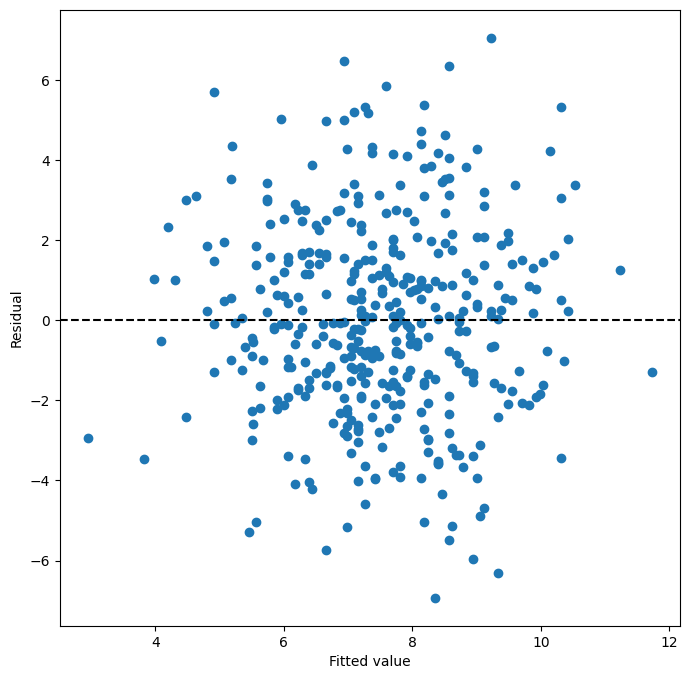

In [38]:
ax = subplots(figsize=(8,8))[1]
ax.scatter(results1.fittedvalues, results1.resid)
ax.set_xlabel('Fitted value')
ax.set_ylabel('Residual')
ax.axhline(0, c='k', ls='--');

In [40]:
influence = results1.get_influence()
studentized_residuals = influence.resid_studentized_internal


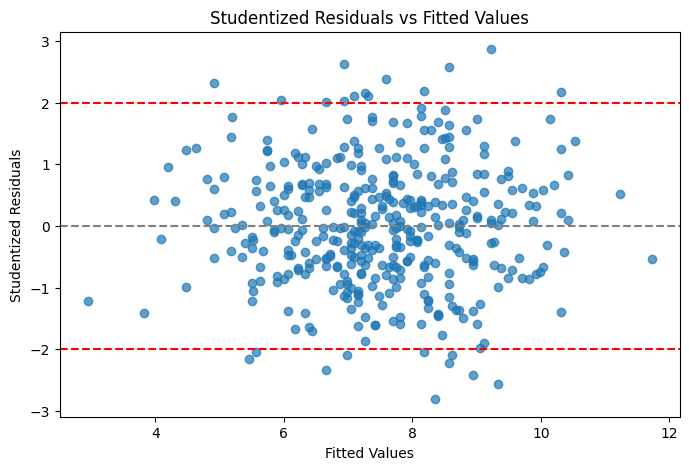

In [44]:
plt.figure(figsize=(8, 5))
plt.scatter(results1.fittedvalues, studentized_residuals, alpha=0.7)
plt.axhline(y=0, color='gray', linestyle='--')
plt.axhline(y=2, color='red', linestyle='--')
plt.axhline(y=-2, color='red', linestyle='--')
plt.xlabel('Fitted Values')
plt.ylabel('Studentized Residuals')
plt.title('Studentized Residuals vs Fitted Values')
plt.show()

In [46]:
for i, resid in enumerate(studentized_residuals):
    if abs(resid) > 2:
        print(f"Index {i} is an outlier with studentized residual: {resid:.3f} \n")

Index 17 is an outlier with studentized residual: 2.109 

Index 25 is an outlier with studentized residual: 2.581 

Index 28 is an outlier with studentized residual: -2.419 

Index 30 is an outlier with studentized residual: 2.184 

Index 49 is an outlier with studentized residual: 2.321 

Index 50 is an outlier with studentized residual: -2.811 

Index 57 is an outlier with studentized residual: -2.336 

Index 62 is an outlier with studentized residual: -2.097 

Index 68 is an outlier with studentized residual: 2.623 

Index 82 is an outlier with studentized residual: 2.016 

Index 98 is an outlier with studentized residual: 2.102 

Index 106 is an outlier with studentized residual: -2.156 

Index 143 is an outlier with studentized residual: -2.053 

Index 209 is an outlier with studentized residual: -2.563 

Index 258 is an outlier with studentized residual: -2.097 

Index 297 is an outlier with studentized residual: -2.230 

Index 298 is an outlier with studentized residual: 2.046 


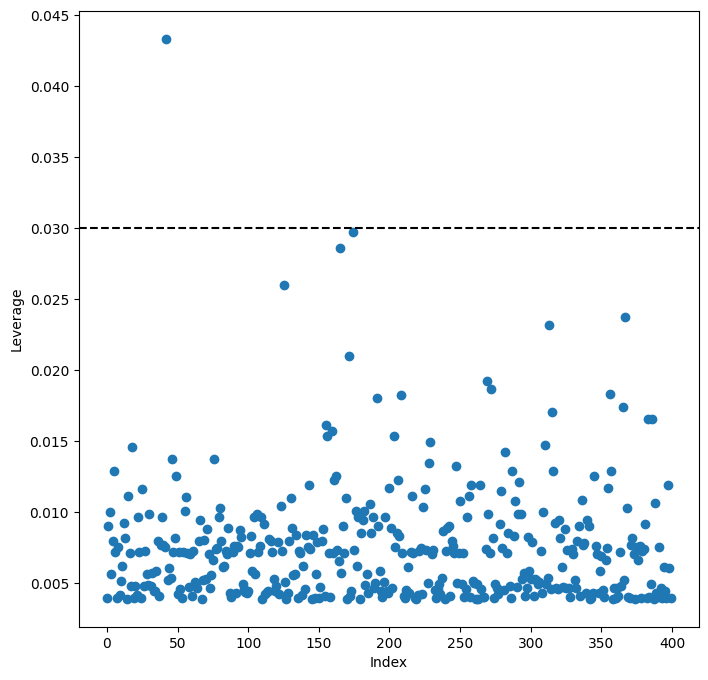

In [51]:
leverage = influence.hat_matrix_diag
threshold = np.average(influence.hat_matrix_diag)*4
ax = subplots(figsize=(8,8))[1]
ax.scatter(np.arange(X.shape[0]), influence.hat_matrix_diag)
ax.set_xlabel('Index')
ax.set_ylabel('Leverage')
ax.axhline(threshold, c='k', ls='--')
np.argmax(leverage);

In [52]:
high_leverage_indices = np.where(leverage > threshold)[0]
print(f"High leverage indices: {high_leverage_indices}")

high_leverage_points = Carseats.iloc[high_leverage_indices]
print(high_leverage_points)

High leverage indices: [42]
    Sales  CompPrice  Income  Advertising  Population  Price ShelveLoc  Age  \
42  10.43         77      69            0          25     24    Medium   50   

    Education Urban  US  
42         18   Yes  No  
